In [1]:

!pip install transformers scikit-learn torch torchvision torchaudio --quiet
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import DistilBertTokenizer, DistilBertModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

import json, os
from tqdm import tqdm


In [2]:
import glob

json_folder_path = r'E:\IMDB\Final'

json_files = glob.glob(os.path.join(json_folder_path, '*.json'))

dataset = []
for file in json_files:
    with open(file, 'r', encoding='utf-8') as f:
        try:
            data = json.load(f)
            dataset.append(data)
        except Exception as e:
            print(f"Error loading {file}: {e}")

print("Total entries loaded: ", len(dataset))


Total entries loaded:  98


In [3]:
genre_names = ['action', 'adventure', 'animation', 'biography', 'comedy', 'crime',
               'documentary', 'drama', 'family', 'fantasy', 'film-noir', 'history',
               'horror', 'music', 'musical', 'mystery', 'news', 'romance', 'sci-fi',
               'short', 'sport', 'thriller', 'war', 'western']

genre_names_lower = [g.lower() for g in genre_names]

texts = []
labels = []

texts = []
labels = []

for entry in dataset:
    plot_raw = entry.get('plot', '')
    plot = " ".join(plot_raw).strip() if isinstance(plot_raw, list) else plot_raw.strip()
    
    genres = [g.lower() for g in entry.get('genres', [])]
    valid_genres = [g for g in genres if g in genre_names_lower]

    if plot and valid_genres:
        texts.append(plot)
        labels.append([1 if g in valid_genres else 0 for g in genre_names_lower])

print("Total valid samples: ", len(texts))
print("Sample plot: ", texts[0][:100], "...")
print("Sample label: ", labels[0])



Total valid samples:  98
Sample plot:  A stationary camera looks at a large anvil with a blacksmith behind it and one on either side. The s ...
Sample label:  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0]


In [4]:
from sklearn.model_selection import train_test_split

train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts, labels, test_size=0.5, random_state=42, shuffle=True
)

print("Train samples: ", len(train_texts))
print("Validation samples: ", len(val_texts))


Train samples:  49
Validation samples:  49


In [5]:
from transformers import DistilBertTokenizer

tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=512, return_tensors='pt')
val_encodings = tokenizer(val_texts, truncation=True, padding=True, max_length=512, return_tensors='pt')

print("Tokenization complete.")
print("Example tokenized input IDs:", train_encodings['input_ids'][0][:10])
from transformers import DistilBertTokenizer

Tokenization complete.
Example tokenized input IDs: tensor([  101,  2006,  1996, 20911,  1997,  2162,  1010,  8318,  1012,  3158])


In [6]:
class IMDBDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.float)
        return item

train_dataset = IMDBDataset(train_encodings, train_labels)
val_dataset = IMDBDataset(val_encodings, val_labels)

print("📦 PyTorch datasets created!")


📦 PyTorch datasets created!


In [7]:
class GenreClassifier(nn.Module):
    def __init__(self, num_labels=24):
        super(GenreClassifier, self).__init__()
        self.bert = DistilBertModel.from_pretrained('distilbert-base-uncased')
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)
    
    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_output = outputs.last_hidden_state[:, 0]  
        cls_output = self.dropout(cls_output)
        logits = self.classifier(cls_output)
        return torch.sigmoid(logits)  

model = GenreClassifier(num_labels=len(genre_names))

In [8]:
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4)


criterion = nn.BCELoss()  
optimizer = AdamW(model.parameters(), lr=5e-5)

print("Dataloaders and optimizer ready.")
print(f"Model parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Dataloaders and optimizer ready.
Model parameters: 66,381,336


In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

epochs = 5
for epoch in range(epochs):
    model.train()
    total_loss = 0

    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1} | Training Loss: {avg_loss:.4f}")

Epoch 1 | Training Loss: 0.4945
Epoch 2 | Training Loss: 0.3139
Epoch 3 | Training Loss: 0.3000
Epoch 4 | Training Loss: 0.2672
Epoch 5 | Training Loss: 0.2598


In [10]:
model.eval()
predictions = []
true_labels = []

with torch.no_grad():
    for batch in val_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids, attention_mask)
        preds = (outputs > 0.3).int().cpu().numpy()
        labels = labels.cpu().numpy()

        predictions.extend(preds)
        true_labels.extend(labels)

In [11]:
def decode_genres(multihot_vector):
    return [genre_names[i] for i, val in enumerate(multihot_vector) if val == 1]

sample_idx = 0
val_text = val_texts[sample_idx]
true = decode_genres(true_labels[sample_idx])
pred = decode_genres(predictions[sample_idx])

print("Plot:\n", val_text[:300], "...\n")
print("True Genres:", true)
print("Predicted Genres:", pred)


Plot:
 In his first independently produced feature film Buster tells of love and romance through three historical ages: the Stone Age, the Roman Age, and the Modern Age. The misadventures of Buster in three separate historical periods. ...

True Genres: ['comedy']
Predicted Genres: ['comedy', 'drama', 'short']


Micro & Macro F1-score

In [12]:
micro_f1 = f1_score(true_labels, predictions, average='micro', zero_division=0)
macro_f1 = f1_score(true_labels, predictions, average='macro', zero_division=0)

print("Micro F1 Score:", round(micro_f1, 4))
print("Macro F1 Score:", round(macro_f1, 4))

Micro F1 Score: 0.5217
Macro F1 Score: 0.1062


In [13]:
from sklearn.metrics import classification_report
import numpy as np

predictions_np = np.array(predictions)
true_labels_np = np.array(true_labels)
rounded_preds = (predictions_np >= 0.5).astype(int)

report = classification_report(
    true_labels_np,
    rounded_preds,
    target_names=genre_names,
    zero_division=0,  
    output_dict=True  
)

Precision, Recall

In [14]:
print("Precision & Recall per Genre:")
for genre in genre_names:
    precision = report[genre]["precision"]
    recall = report[genre]["recall"]
    print(f"{genre:12} | Precision: {precision:.3f} | Recall: {recall:.3f}")

Precision & Recall per Genre:
action       | Precision: 0.000 | Recall: 0.000
adventure    | Precision: 0.000 | Recall: 0.000
animation    | Precision: 0.000 | Recall: 0.000
biography    | Precision: 0.000 | Recall: 0.000
comedy       | Precision: 0.444 | Recall: 0.842
crime        | Precision: 0.000 | Recall: 0.000
documentary  | Precision: 0.000 | Recall: 0.000
drama        | Precision: 0.667 | Recall: 0.963
family       | Precision: 0.000 | Recall: 0.000
fantasy      | Precision: 0.125 | Recall: 0.200
film-noir    | Precision: 0.000 | Recall: 0.000
history      | Precision: 0.000 | Recall: 0.000
horror       | Precision: 0.000 | Recall: 0.000
music        | Precision: 0.000 | Recall: 0.000
musical      | Precision: 0.000 | Recall: 0.000
mystery      | Precision: 0.000 | Recall: 0.000
news         | Precision: 0.000 | Recall: 0.000
romance      | Precision: 0.455 | Recall: 0.455
sci-fi       | Precision: 0.000 | Recall: 0.000
short        | Precision: 0.400 | Recall: 1.000
sport     

Hamming Loss

In [15]:
from sklearn.metrics import hamming_loss

hl = hamming_loss(true_labels, predictions)
print(f"Hamming Loss: {hl:.4f}")


Hamming Loss: 0.1029


Print F1-scores for top 5 frequent genres

In [16]:
genre_counts = np.sum(true_labels_np, axis=0)
top5_indices = genre_counts.argsort()[::-1][:5]
print("Per-genre F1-scores (Top 5 Frequent Genres):")
print(f"{'Genre':12} | {'F1 Score':>8} | {'Samples':>7}")
print("-" * 35)

for idx in top5_indices:
    genre = genre_names[idx]
    f1 = report[genre]["f1-score"]
    count = genre_counts[idx]
    print(f"{genre:12} | {f1:.3f}     | {count:>7}")

Per-genre F1-scores (Top 5 Frequent Genres):
Genre        | F1 Score | Samples
-----------------------------------
drama        | 0.788     |    27.0
comedy       | 0.582     |    19.0
short        | 0.571     |    18.0
romance      | 0.455     |    11.0
crime        | 0.000     |     6.0


Confusion matrix

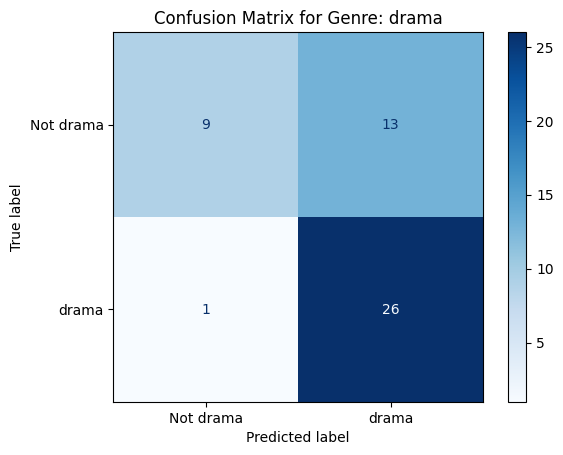

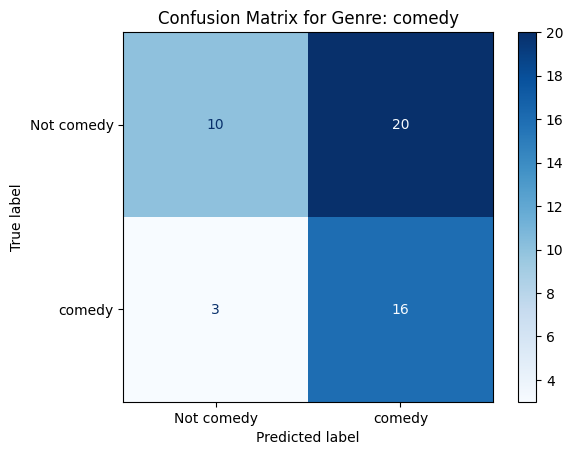

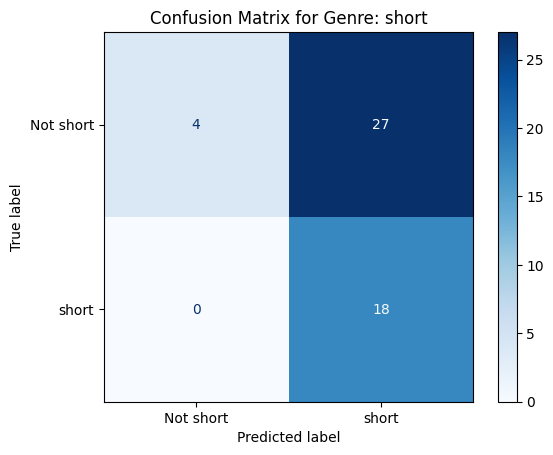

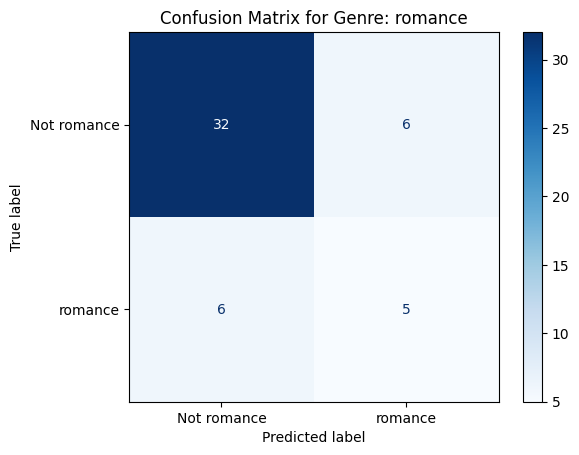

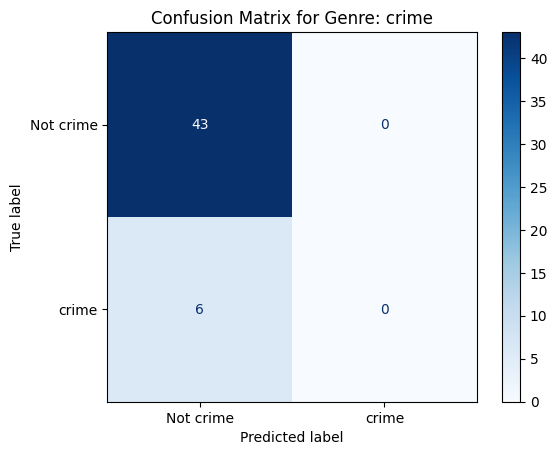

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for idx in top5_indices:
    genre = genre_names[idx]
    y_true = true_labels_np[:, idx]
    y_pred = rounded_preds[:, idx]

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Not " + genre, genre])
    disp.plot(cmap='Blues')
    plt.title(f"Confusion Matrix for Genre: {genre}")
    plt.show()

Display 3 correctly classified and 3 incorrect predictions with movie poster, text, and predicted genres.

In [18]:
import numpy as np

def decode_genres(binary_vec):
    return [genre_names[i] for i, val in enumerate(binary_vec) if val == 1]

shown_correct = 0
shown_incorrect = 0

print("Qualitative Examples (Text + Predicted Genres)\n")

for i in range(len(true_labels_np)):
    if shown_correct >= 3 and shown_incorrect >= 3:
        break

    true = true_labels_np[i]
    pred = rounded_preds[i]

    if np.array_equal(true, pred) and shown_correct < 3:
        print(f"Correct Prediction {shown_correct + 1}")
        shown_correct += 1
    elif not np.array_equal(true, pred) and shown_incorrect < 3:
        print(f"Incorrect Prediction {shown_incorrect + 1}")
        shown_incorrect += 1
    else:
        continue

    print("True Genres     :", decode_genres(true))
    print("Predicted Genres:", decode_genres(pred))
   


Qualitative Examples (Text + Predicted Genres)

Incorrect Prediction 1
True Genres     : ['comedy']
Predicted Genres: ['comedy', 'drama', 'short']
Incorrect Prediction 2
True Genres     : ['comedy', 'short']
Predicted Genres: ['comedy', 'drama', 'short']
Correct Prediction 1
True Genres     : ['comedy', 'drama', 'short']
Predicted Genres: ['comedy', 'drama', 'short']
Incorrect Prediction 3
True Genres     : ['drama', 'fantasy', 'horror', 'romance']
Predicted Genres: ['comedy', 'drama', 'short']
Correct Prediction 2
True Genres     : ['short']
Predicted Genres: ['short']
Correct Prediction 3
True Genres     : ['comedy', 'short']
Predicted Genres: ['comedy', 'short']


ROC Curve Code for Top 5 Genres

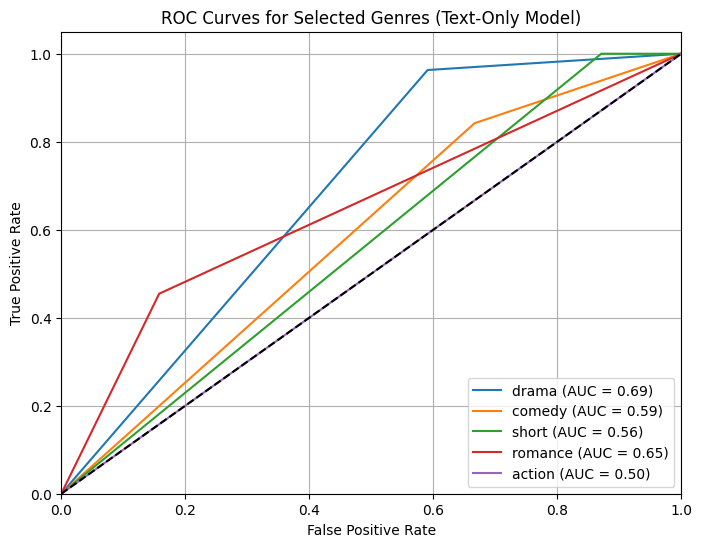

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

predictions_np = np.array(predictions)
true_labels_np = np.array(true_labels)

selected_indices = [genre_names.index('drama'), genre_names.index('comedy'), genre_names.index('short'),genre_names.index('romance'),genre_names.index('action')]

plt.figure(figsize=(8, 6))

for idx in selected_indices:
    fpr, tpr, _ = roc_curve(true_labels_np[:, idx], predictions_np[:, idx])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{genre_names[idx]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Selected Genres (Text-Only Model)')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig("roc_curves_TEXT.png", dpi=300)
plt.show()


Measure Inference Time (on CPU)

In [35]:
import torch
import time

batch_sizes = [1, 16]
seq_len = 64  
vocab_size = 30522  

device = torch.device("cpu")
model.to(device)
model.eval()

print("Inference Time on CPU:")
for batch_size in batch_sizes:
    total_time = 0
    steps = 10 

    for _ in range(steps):
        input_ids = torch.randint(0, vocab_size, (batch_size, seq_len)).long().to(device)
        attention_mask = torch.ones((batch_size, seq_len)).long().to(device)

        start = time.time()
        with torch.no_grad():
            _ = model(input_ids=input_ids, attention_mask=attention_mask)
        end = time.time()

        total_time += (end - start)

    avg_time = total_time / steps
    print(f"Batch Size = {batch_size} → Avg Inference Time: {avg_time:.4f} sec")


Inference Time on CPU:
Batch Size = 1 → Avg Inference Time: 0.1304 sec
Batch Size = 16 → Avg Inference Time: 0.4975 sec


In [45]:
from sklearn.metrics import accuracy_score
import torch

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for batch in val_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits if hasattr(outputs, 'logits') else outputs

        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).int()

        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())

# Stack all batches
y_pred = torch.cat(all_preds, dim=0).numpy()
y_true = torch.cat(all_labels, dim=0).numpy()

# Compute subset accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Subset Accuracy: {accuracy:.4f}")


Subset Accuracy: 0.0000


In [21]:
torch.save(model.state_dict(), "model.pt")

import os
model_size = os.path.getsize("model.pt") / (1024 * 1024)
print(f"Model size: {model_size:.2f} MB")


Model size: 253.26 MB


In [22]:
from torchinfo import summary

summary(model, input_data={
    "input_ids": torch.randint(0, 30522, (1, 64)),
    "attention_mask": torch.ones((1, 64)).long()
})


Layer (type:depth-idx)                                  Output Shape              Param #
GenreClassifier                                         [1, 24]                   --
├─DistilBertModel: 1-1                                  [1, 64, 768]              --
│    └─Embeddings: 2-1                                  [1, 64, 768]              --
│    │    └─Embedding: 3-1                              [1, 64, 768]              23,440,896
│    │    └─Embedding: 3-2                              [1, 64, 768]              393,216
│    │    └─LayerNorm: 3-3                              [1, 64, 768]              1,536
│    │    └─Dropout: 3-4                                [1, 64, 768]              --
│    └─Transformer: 2-2                                 [1, 64, 768]              --
│    │    └─ModuleList: 3-5                             --                        42,527,232
├─Dropout: 1-2                                          [1, 768]                  --
├─Linear: 1-3                       

Bar plot: Accuracy vs Inference Time

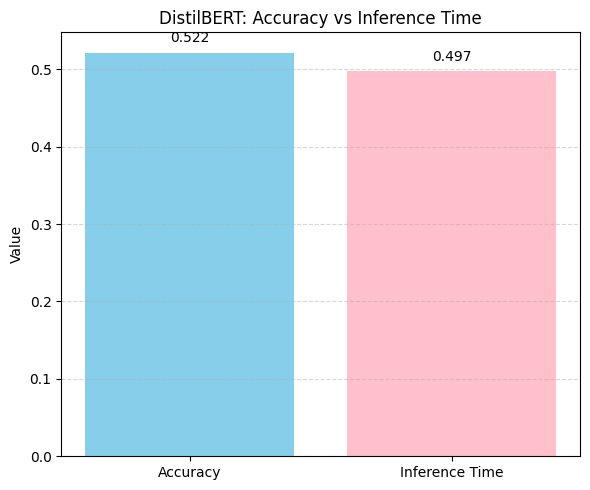

In [49]:
import matplotlib.pyplot as plt

model_name = "DistilBERT"
accuracy = 0.5217             
inference_time = 0.4975     

metrics = ['Accuracy', 'Inference Time']
values = [accuracy, inference_time]

plt.figure(figsize=(6, 5))
bars = plt.bar(metrics, values, color=['skyblue', 'pink'])

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f'{yval:.3f}', ha='center', va='bottom')

plt.title(f"{model_name}: Accuracy vs Inference Time")
plt.ylabel("Value")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("accuracy_vs_inference_TEXT.png", dpi=300)
plt.show()


Bar plot: Model Size vs F1-score

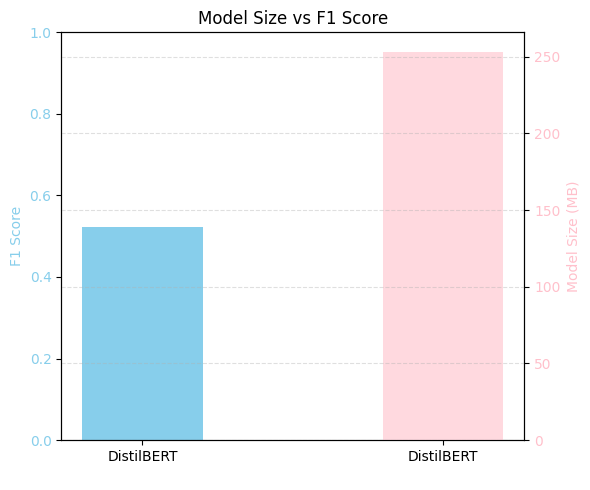

In [54]:
import matplotlib.pyplot as plt

model_names = ['DistilBERT']
f1_scores = [0.5217]           
model_sizes = [253.26]         

fig, ax1 = plt.subplots(figsize=(6, 5))

bar1 = ax1.bar(model_names, f1_scores, width=0.4, label='F1 Score', color='skyblue')
ax1.set_ylabel('F1 Score', color='skyblue')
ax1.tick_params(axis='y', labelcolor='skyblue')
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()
bar2 = ax2.bar([x + '\n' for x in model_names], model_sizes, width=0.4, label='Model Size (MB)', color='pink', alpha=0.6)
ax2.set_ylabel('Model Size (MB)', color='pink')
ax2.tick_params(axis='y', labelcolor='pink')

plt.title('Model Size vs F1 Score')
fig.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.savefig("model_size_vs_f1Score_TEXT.png", dpi=300)
plt.show()

In [51]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss, classification_report

micro_f1 = f1_score(true_labels_np, rounded_preds, average="micro", zero_division=0)
macro_f1 = f1_score(true_labels_np, rounded_preds, average="macro", zero_division=0)
precision = precision_score(true_labels_np, rounded_preds, average="micro", zero_division=0)
recall = recall_score(true_labels_np, rounded_preds, average="micro", zero_division=0)
hloss = hamming_loss(true_labels_np, rounded_preds)

report = classification_report(
    true_labels_np,
    rounded_preds,
    target_names=genre_names,
    output_dict=True,
    zero_division=0
)

class_f1_scores = {label: values["f1-score"] for label, values in report.items() if label in genre_names}

summary_rows = {
    "Metric": ["Micro F1-score", "Macro F1-score", "Precision", "Recall", "Hamming Loss"],
    "Score": [micro_f1, macro_f1, precision, recall, hloss]
}

summary_df = pd.DataFrame(summary_rows)

genre_f1_df = pd.DataFrame({
    "Metric": [f"F1-{genre}" for genre in class_f1_scores.keys()],
    "Score": list(class_f1_scores.values())
})

results_df = pd.concat([summary_df, genre_f1_df], ignore_index=True)
results_df.to_csv("Text_results.csv", index=False)
print("Saved Text_results.csv")

Saved Text_results.csv


In [53]:
import pandas as pd

benchmark_data = {
    "Model": ["Text Only"],
    "F1-score": [0.5217],
    "Accuracy": [0.5217],
    "Inference Time (s/sample)": [0.4975],
    "Model Size (MB)": [253.26],
    "Parameters (Millions)": [66381336]
}

benchmark_df = pd.DataFrame(benchmark_data)
print("TEXT ONLY Benchmark Summary Table")
display(benchmark_df)

benchmark_df.to_csv("benchmark_summary_TEXT.csv", index=False)


TEXT ONLY Benchmark Summary Table


,Model,F1-score,Accuracy,Inference Time (s/sample),Model Size (MB),Parameters (Millions)
0,Text Only,0.5217,0.5217,0.4975,253.26,66381336
